# How the sources of risk change over time

The decomposition of [`03_strategy_decomposition`](03_strategy_decomposition.ipynb) in rolling windows, as Figure 1 of the paper does for two US portfolios: 60-month windows of monthly returns, and 252-day windows of daily returns. The factors are orthogonalized again inside each window, so the components add up to 100% in every window. Each point is the window that ends on that date.

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from orthofactors.data import (load_brazil_factors, load_brazil_strategies, to_monthly, BRAZIL_FACTORS,
                               BRAZIL_STRATEGIES, MONTHLY_SAMPLE)
from orthofactors.orthogonalization import orthogonalize_swl
from orthofactors.decomposition import rolling_window_regression
from orthofactors.plotting import set_style, factor_colors, plot_decomposition, DIVERGING

set_style()
Path('results').mkdir(exist_ok = True)
Path('docs').mkdir(exist_ok = True)
colors = factor_colors(BRAZIL_FACTORS)

In [2]:
factors_daily = load_brazil_factors()[BRAZIL_FACTORS]
strategies_daily = load_brazil_strategies()
factors = to_monthly(factors_daily).loc[MONTHLY_SAMPLE]
strategies = to_monthly(strategies_daily).loc[MONTHLY_SAMPLE]

# Rolling decomposition, with the factors orthogonalized in each window
rolling_monthly = rolling_window_regression(strategies, factors, window_days = 60, orthogonalize = orthogonalize_swl)
rolling_daily = rolling_window_regression(strategies_daily, factors_daily, window_days = 252, orthogonalize = orthogonalize_swl)

for name, rolling in [('60-month', rolling_monthly), ('252-day', rolling_daily)]:
    gap = max((rolling[s][BRAZIL_FACTORS].sum(axis = 1) - rolling[s]['R2']).abs().max() for s in BRAZIL_STRATEGIES)
    print(f'{name} windows: {len(rolling)}, ending from {rolling.index[0]:%Y-%m-%d} to {rolling.index[-1]:%Y-%m-%d}; '
          f'largest gap between the sum of DR² and R²: {gap:.1e}')

60-month windows: 138, ending from 2015-01-31 to 2026-06-30; largest gap between the sum of DR² and R²: 6.8e-15
252-day windows: 3906, ending from 2011-01-04 to 2026-07-23; largest gap between the sum of DR² and R²: 1.7e-14


## 60-month windows

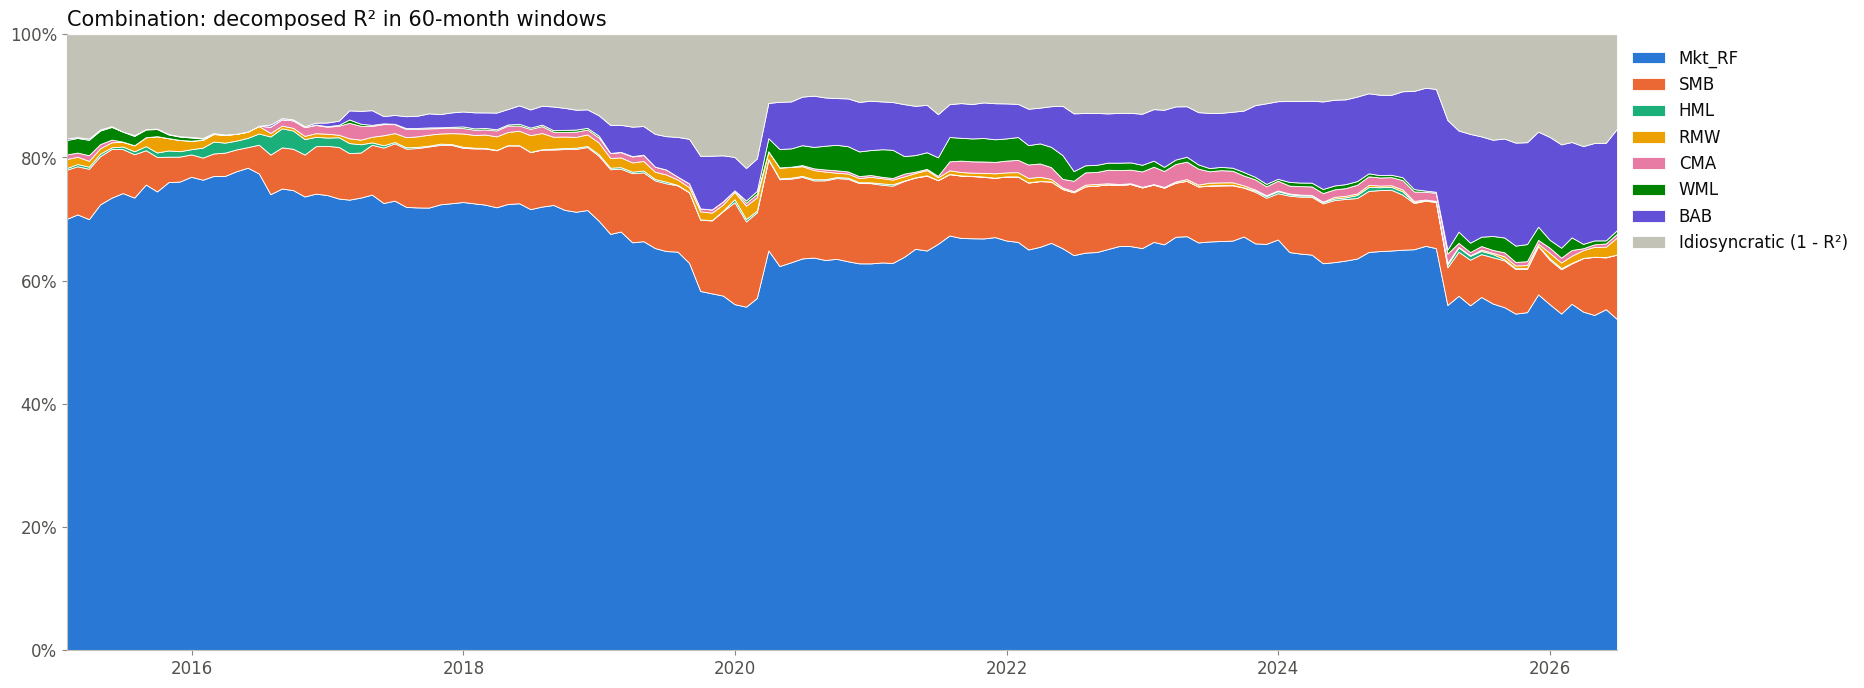

In [3]:
fig, ax = plt.subplots()
plot_decomposition(ax, rolling_monthly['Combination'], BRAZIL_FACTORS, 'Combination: decomposed R² in 60-month windows')
plt.show()

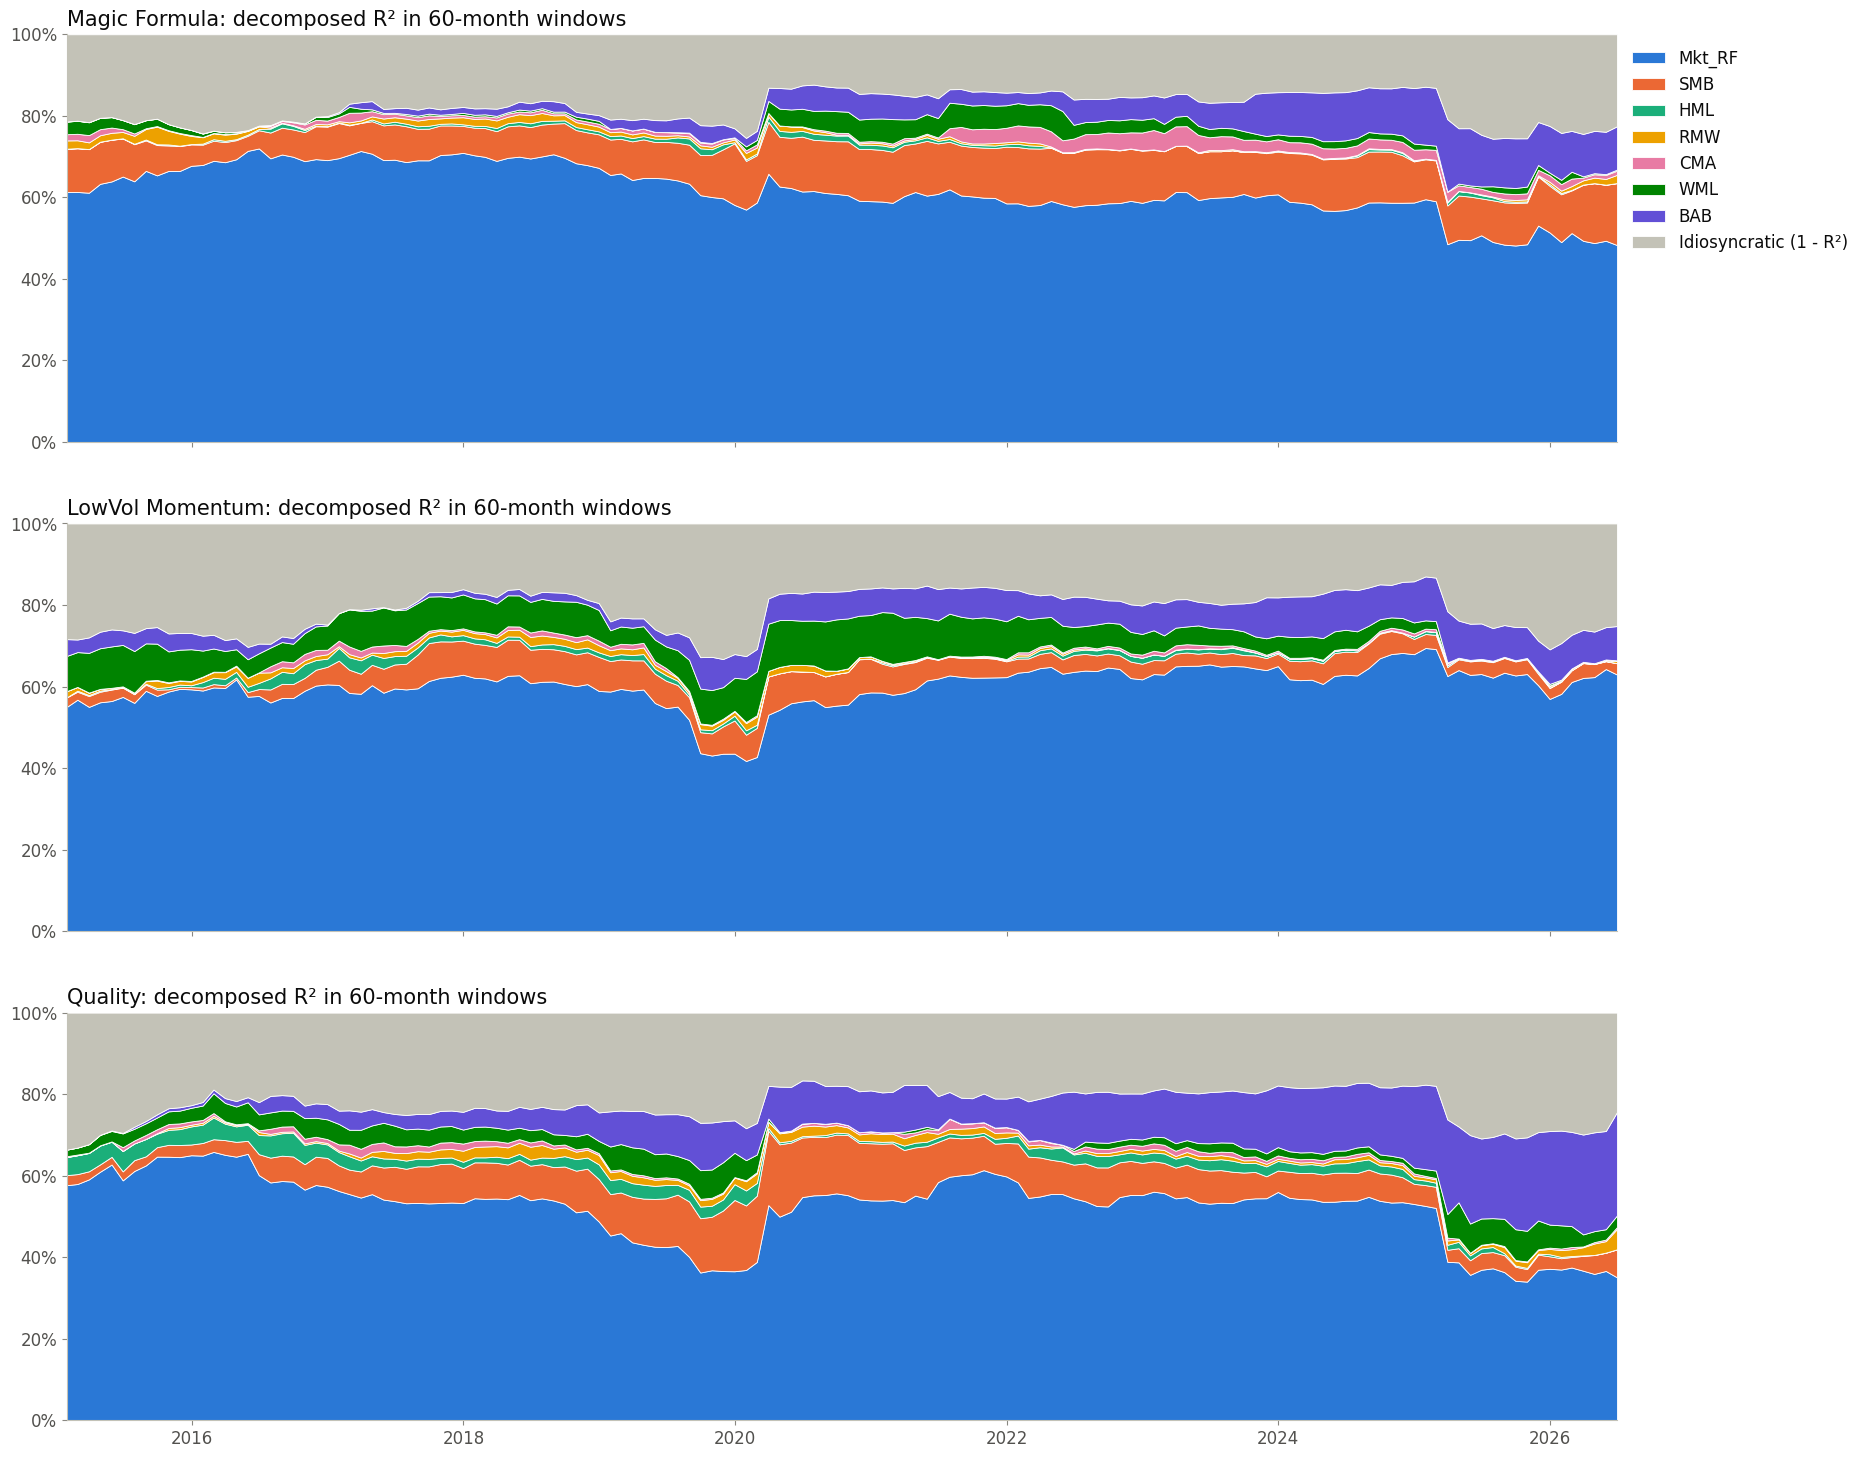

In [4]:
fig, axes = plt.subplots(3, 1, figsize = (20, 18), sharex = True)
for i, (ax, strategy) in enumerate(zip(axes, ['Magic Formula', 'LowVol Momentum', 'Quality'])):
    plot_decomposition(ax, rolling_monthly[strategy], BRAZIL_FACTORS, f'{strategy}: decomposed R² in 60-month windows')
    if i > 0:
        ax.get_legend().remove()
plt.show()

In [5]:
# First and last window, and the range over the windows, for the Combination
combination = rolling_monthly['Combination'][BRAZIL_FACTORS + ['idiosyncratic']]
pd.DataFrame({f'2010-02 to {combination.index[0]:%Y-%m}': combination.iloc[0],
              f'{combination.index[-1] - pd.DateOffset(months = 59):%Y-%m} to {combination.index[-1]:%Y-%m}': combination.iloc[-1],
              'Lowest': combination.min(), 'Highest': combination.max()}).T.style.format('{:.1%}')

component,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
2010-02 to 2015-01,70.1%,8.0%,0.3%,1.5%,0.7%,2.3%,0.2%,16.9%
2021-07 to 2026-06,53.8%,10.5%,0.0%,2.8%,0.6%,0.6%,16.4%,15.3%
Lowest,53.8%,3.3%,0.0%,0.1%,0.0%,0.0%,0.0%,8.7%
Highest,78.3%,16.5%,3.1%,2.8%,2.8%,4.6%,21.0%,21.7%


In [6]:
# Average of each component over the 60-month windows, by strategy
pd.DataFrame({s: rolling_monthly[s][BRAZIL_FACTORS + ['idiosyncratic']].mean() for s in BRAZIL_STRATEGIES}).T.style.format('{:.1%}')

component,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
Combination,66.6%,9.2%,0.4%,0.9%,1.0%,1.2%,7.0%,13.5%
Magic Formula,61.7%,10.3%,0.5%,0.8%,1.6%,2.0%,5.0%,18.1%
LowVol Momentum,60.1%,4.8%,0.8%,0.7%,0.5%,6.4%,5.4%,21.3%
Quality,52.2%,8.0%,2.2%,1.2%,0.8%,2.9%,9.9%,22.7%


The market is always the largest source, but its share fell from 70% in the first window (2010–2015) to 54% in the last one (2021–2026), the lowest of all windows. BAB took most of that space, from 0.2% in the first window to 16% in the last, with a peak of 21%. Size moved between 3% and 17%, value, profitability, investment and momentum never went above 5%, and the idiosyncratic share stayed between 9% and 22%. The sleeves follow the same pattern, with more momentum in LowVol Momentum (6.4% on average) and more BAB in Quality (9.9%).

## 252-day windows

Daily windows react faster. The white dashed lines mark the start of the 2014–2016 recession (second quarter of 2014, as dated by CODACE), the COVID-19 crash of March 2020 and the first increase of the SELIC rate in March 2021, at the start of a cycle that took it from 2% to 13.75%.

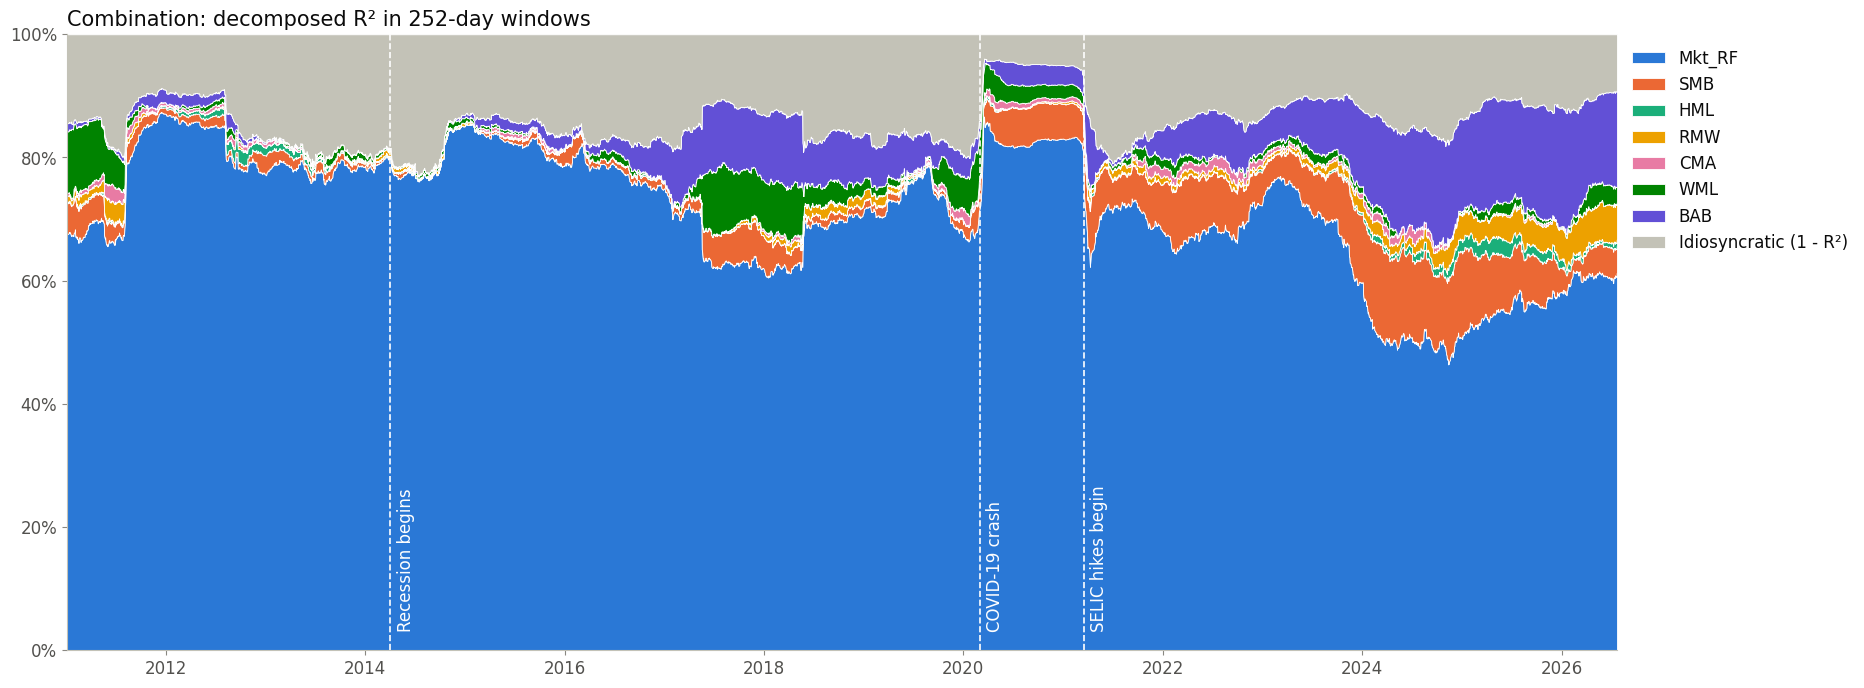

In [7]:
events = {'Recession begins': '2014-04-01', 'COVID-19 crash': '2020-03-01', 'SELIC hikes begin': '2021-03-17'}

fig, ax = plt.subplots()
plot_decomposition(ax, rolling_daily['Combination'], BRAZIL_FACTORS, 'Combination: decomposed R² in 252-day windows')
for label, day in events.items():
    ax.axvline(pd.Timestamp(day), color = '#ffffff', linestyle = '--', linewidth = 1.2)
    ax.text(pd.Timestamp(day) + pd.Timedelta(days = 25), 0.03, label, rotation = 90, ha = 'left', va = 'bottom',
            fontsize = 12, color = '#ffffff')
fig.savefig('docs/combination_rolling_decomposition.png', dpi = 100, bbox_inches = 'tight')
plt.show()

In [8]:
# Average of the daily windows that end in each year
yearly = rolling_daily['Combination'][BRAZIL_FACTORS + ['idiosyncratic']].groupby(rolling_daily.index.year).mean()
lowest = rolling_daily[('Combination', 'idiosyncratic')]
print(f'Lowest idiosyncratic share: {lowest.min():.1%}, in the window that ends on {lowest.idxmin():%Y-%m-%d}')
yearly.style.format('{:.1%}')

Lowest idiosyncratic share: 3.9%, in the window that ends on 2020-03-18


component,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
Date,,,,,,,,
2011,74.4%,3.2%,0.2%,1.4%,1.1%,5.2%,1.1%,13.5%
2012,82.9%,1.4%,1.1%,0.1%,0.6%,0.5%,1.4%,12.1%
2013,78.1%,1.5%,0.7%,0.1%,0.2%,0.6%,0.1%,18.7%
2014,79.2%,0.2%,0.1%,0.5%,0.0%,0.5%,0.1%,19.3%
2015,82.4%,0.8%,0.1%,0.1%,0.5%,0.3%,1.6%,14.3%
2016,77.7%,1.3%,0.1%,0.0%,0.1%,0.7%,3.0%,17.1%
2017,66.1%,4.0%,0.0%,0.3%,0.1%,6.1%,9.9%,13.5%
2018,66.6%,2.3%,0.0%,1.3%,0.3%,5.1%,9.2%,15.1%
2019,73.2%,1.0%,0.2%,0.6%,0.5%,2.1%,5.4%,17.1%


The daily windows show when the shift happened. Until 2016 the market explained about 80% of the daily variance and BAB at most 3%. BAB first grew in 2017 and 2018, together with momentum, to about 10%. It grew again from 2022 and reached about 16% in the windows that end in 2024 to 2026, while the share of the market fell to between 51% and 60% and that of size rose to 13% in 2024. Crashes push everything into the market: the lowest idiosyncratic share, 3.9%, is in the window that ends on 2020-03-18, during the COVID-19 crash, when almost all stocks fell together.

The decomposition shows when the low-beta dimension became a larger part of the risk, not why. The timing coincides with the rise of the SELIC rate after 2021, but this notebook does not test a cause.

## How the components move together

The paper finds that the components trade off against each other over time. The heatmap shows the correlations between the 60-month decomposed $R^2$ of each factor for the Combination.

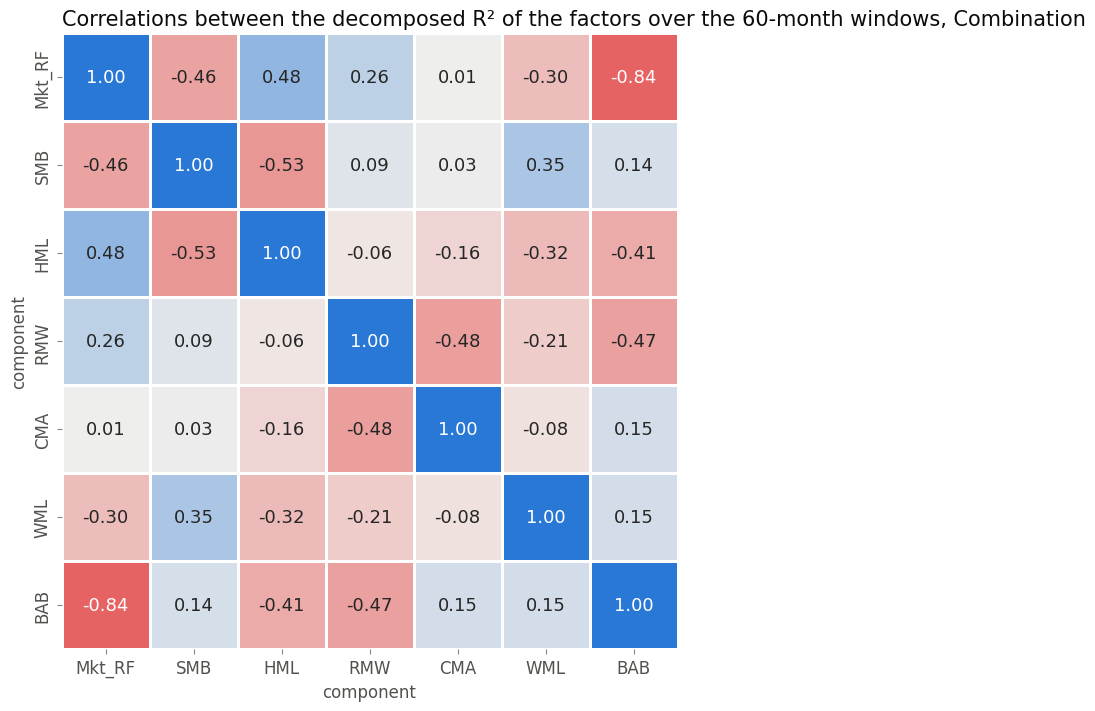

In [9]:
fig, ax = plt.subplots(figsize = (10, 8))
sns.heatmap(combination[BRAZIL_FACTORS].corr().round(2) + 0.0, annot = True, fmt = '.2f', cmap = DIVERGING, vmin = -1, vmax = 1,
            square = True, cbar = False, linewidths = 2, linecolor = 'white', annot_kws = {'size': 13}, ax = ax)
ax.set_title('Correlations between the decomposed R² of the factors over the 60-month windows, Combination')
ax.grid(False)
plt.show()

The strongest link is between the market and BAB: across the windows, when the share of BAB rises, the share of the market falls, with a correlation of −0.84. They are the most correlated pair of factors, and the decomposition splits their common risk between them. Size and value also move against each other (−0.53), and so do the market and size (−0.46).

## How close the orthogonal factors stay to the originals

The resemblance $\text{diag}(\Psi)$ in each 60-month window.

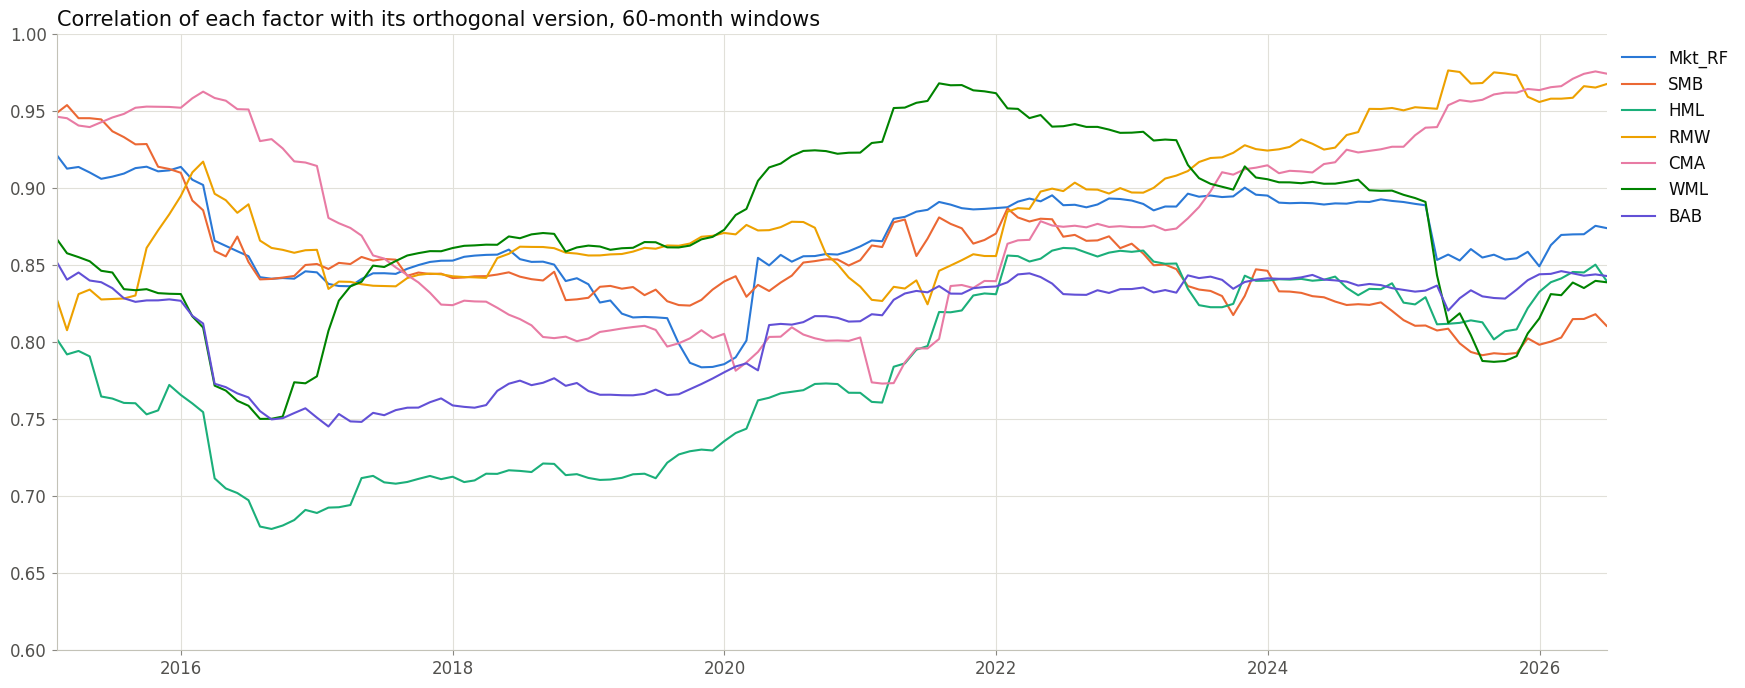

,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB
min,0.784,0.792,0.679,0.808,0.773,0.750,0.745
median,0.866,0.844,0.773,0.873,0.876,0.867,0.828
max,0.922,0.954,0.861,0.977,0.976,0.968,0.852


In [10]:
resemblance = {}
for end in range(60, len(factors) + 1):
    _, _, Psi = orthogonalize_swl(factors.iloc[end - 60:end], return_matrices = True)
    resemblance[factors.index[end - 1]] = np.diag(Psi)
resemblance = pd.DataFrame(resemblance, index = BRAZIL_FACTORS).T

fig, ax = plt.subplots()
for factor in BRAZIL_FACTORS:
    ax.plot(resemblance.index, resemblance[factor], color = colors[factor], label = factor)
ax.set_ylim(0.6, 1)
ax.margins(x = 0)
ax.set_title('Correlation of each factor with its orthogonal version, 60-month windows')
ax.legend(loc = 'upper left', bbox_to_anchor = (1.0, 1.0))
plt.show()

resemblance.agg(['min', 'median', 'max']).round(3)

The orthogonal factors stay close to the originals in every window. The median resemblance goes from 0.77 (HML) to 0.88 (CMA), and the lowest value of any factor in any window is 0.68, for HML in the windows that end in 2016. In most windows the resemblance is lower than over the full sample, because the factors are often more correlated within shorter periods.

In [11]:
rolling_monthly.round(4).to_csv('results/rolling_decomposition_60_months.csv')
yearly.round(4).to_csv('results/rolling_decomposition_252_days_by_year.csv')